# Audit and Exploration: AI Exposure Predicts Unemployment Risk

This notebook audits and explores the dataset from Frank et al. (2025), "AI exposure predicts unemployment risk".

Paper: M. R. Frank, Y.-Y. Ahn and E. Moro, "AI exposure predicts unemployment risk: A new approach to technology-driven job loss," *PNAS Nexus*, 2025.

Data: https://github.com/mrfrank8176/unemploymentRisk (two CSV files)

Other sources: Alabama labour force 2015, BLS via FRED: https://fred.stlouisfed.org/data/LAUST010000000000006A

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# URLs for the datasets
unemployment_risk_url = "https://raw.githubusercontent.com/mrfrank8176/unemploymentRisk/main/demoData_unemploymentRisk.csv"
automation_by_state_url = "https://raw.githubusercontent.com/mrfrank8176/unemploymentRisk/main/demoData_automationByState.csv"

# Loading the datasets
df_risk = pd.read_csv(unemployment_risk_url)
df_auto = pd.read_csv(automation_by_state_url)

# Displaying the columns and shapes
print("--- Unemployment Risk Dataset Info ---")
print(f"Shape: {df_risk.shape}")
print(f"Columns: {list(df_risk.columns)}")
display(df_risk.head())

print("\n--- Automation By State Dataset Info ---")
print(f"Shape: {df_auto.shape}")
print(f"Columns: {list(df_auto.columns)}")
display(df_auto.head())

--- Unemployment Risk Dataset Info ---
Shape: (140274, 9)
Columns: ['Unnamed: 0', 'state', 'st', 'year', 'month', '2SOC', 'Unemployment Risk', 'Total Unemployment Rate (%)', 'Unemployment Count']


,Unnamed: 0,state,st,year,month,2SOC,Unemployment Risk,Total Unemployment Rate (%),Unemployment Count
0,0,Alabama,AL,2010,1,11,0.003038,11.448858,4178
1,1,Alabama,AL,2010,2,11,0.002917,11.085179,4077
2,2,Alabama,AL,2010,3,11,0.002931,10.754540,3916
3,3,Alabama,AL,2010,4,11,0.002691,9.846164,3705
4,4,Alabama,AL,2010,5,11,0.002698,9.651209,3521



--- Automation By State Dataset Info ---
Shape: (549, 16)
Columns: ['Unnamed: 0', 'year', 'state', 'month', 'Acemoglu & Autor Comp.Use', 'Acemoglu & Autor R.Cog.', 'Acemoglu & Autor R.Man.', 'ONET Education %college', 'Frey & Osborne auto', 'Arntz et al auto', 'ONET Automation Deg.Auto.', 'Brynjolfsson et al SML', 'Felten et al AI', 'Webb AI', 'Webb Robot', 'Webb Software']


,Unnamed: 0,year,state,month,Acemoglu & Autor Comp.Use,Acemoglu & Autor R.Cog.,Acemoglu & Autor R.Man.,ONET Education %college,Frey & Osborne auto,Arntz et al auto,ONET Automation Deg.Auto.,Brynjolfsson et al SML,Felten et al AI,Webb AI,Webb Robot,Webb Software
0,0,2010,AK,1,0.650780,-0.385926,-0.623702,0.366802,0.174588,0.142123,0.218134,0.563278,3.558259,65.016967,23.694087,46.263239
1,1,2010,AL,1,0.634850,-0.370374,-0.586113,0.336282,0.123737,0.139628,0.218478,0.562817,3.544763,65.972539,23.217806,45.789565
2,2,2010,AR,1,0.625480,-0.346294,-0.630219,0.334520,0.160773,0.159131,0.217509,0.558524,3.535279,64.181343,22.657812,44.472914
3,3,2010,AZ,1,0.655891,-0.337029,-0.635396,0.352782,0.152755,0.161317,0.220636,0.567099,3.565156,66.706672,24.056527,46.714463
4,4,2010,CA,1,0.965681,0.355029,-0.438817,0.006700,0.075879,0.092822,0.159536,0.435019,2.682811,60.639335,27.268805,52.160351


The Unemployment Risk dataset has 140,274 rows and 9 columns.

The Automation by State dataset has 549 rows and 16 columns.

Both the datasets have an unnamed column which seems to be the row index.

In [3]:
# Checking if 'Unnamed: 0' is just a copy of the index, and drop it if True
risk_unnamed_is_index = (df_risk['Unnamed: 0'] == df_risk.index).all()
auto_unnamed_is_index = (df_auto['Unnamed: 0'] == df_auto.index).all()

print(f"Is 'Unnamed: 0' in df_risk a copy of the index? {risk_unnamed_is_index}")
print(f"Is 'Unnamed: 0' in df_auto a copy of the index? {auto_unnamed_is_index}")

if risk_unnamed_is_index:
    df_risk = df_risk.drop(columns=['Unnamed: 0'])

if auto_unnamed_is_index:
    df_auto = df_auto.drop(columns=['Unnamed: 0'])

# Renaming the columns
rename_dict = {
    '2SOC': 'soc',
    'Unemployment Risk': 'risk',
    'Total Unemployment Rate (%)': 'state_rate',
    'Unemployment Count': 'claimants'
}
df_risk = df_risk.rename(columns=rename_dict)

# Printing data types of df_risk
print("\n--- df_risk Column Data Types ---")
print(df_risk.dtypes)

# Printing dataset statistics
print("\n--- df_risk Summary Statistics ---")
print(f"Total number of rows: {len(df_risk)}")
print(f"Number of unique states (st): {df_risk['st'].nunique()}")
print(f"Year range: {df_risk['year'].min()} to {df_risk['year'].max()}")
print(f"Number of unique SOC codes: {df_risk['soc'].nunique()}")

# Checking for duplicate rows on the combination of st, year, month, and soc
duplicate_keys = ['st', 'year', 'month', 'soc']
num_duplicates = df_risk.duplicated(subset=duplicate_keys).sum()
print(f"\nNumber of duplicate rows on {duplicate_keys}: {num_duplicates}")

# Counting rows by year splits (<= 2019 vs 2020)
rows_pre_2020 = (df_risk['year'] <= 2019).sum()
rows_2020 = (df_risk['year'] == 2020).sum()
print(f"\nNumber of rows with year <= 2019: {rows_pre_2020}")
print(f"Number of rows with year == 2020: {rows_2020}")

Is 'Unnamed: 0' in df_risk a copy of the index? True
Is 'Unnamed: 0' in df_auto a copy of the index? True

--- df_risk Column Data Types ---
state          object
st             object
year            int64
month           int64
soc             int64
risk          float64
state_rate    float64
claimants       int64
dtype: object

--- df_risk Summary Statistics ---
Total number of rows: 140274
Number of unique states (st): 50
Year range: 2010 to 2020
Number of unique SOC codes: 22

Number of duplicate rows on ['st', 'year', 'month', 'soc']: 0

Number of rows with year <= 2019: 127452
Number of rows with year == 2020: 12822


Dropped the Unnamed: 0 column as it was just a copy of the row index in both the files.  

n = 140,274, which matches the paper exactly with all the years included but the paper says most of its analysis excluded the COVID year (2020) which would give 127,452 rows.

50 states; 2010-2020; 22 unique SOC codes and no duplicate state x year x month x occupation rows.


In [4]:
# Printing the number of NaN values in each column
print("--- Missing (NaN) Values per Column ---")
print(df_risk.isna().sum())

# Printing rows with zero claimants and the minimum value of claimants
zero_claimants_count = (df_risk['claimants'] == 0).sum()
min_claimants = df_risk['claimants'].min()
print(f"\nNumber of rows with zero claimants: {zero_claimants_count}")
print(f"Minimum value of claimants: {min_claimants}")

# Calculating panel completeness (50 states x 11 years x 12 months x 22 SOC codes)
expected_count = 50 * 11 * 12 * 22
actual_count = len(df_risk)
missing_rows = expected_count - actual_count
pct_missing = (missing_rows / expected_count) * 100

print("\n--- Panel Completeness Audit ---")
print(f"Expected rows in complete panel: {expected_count}")
print(f"Actual rows in df_risk: {actual_count}")
print(f"Missing rows: {missing_rows}")
print(f"Percentage missing: {pct_missing:.2f}%")

# Printing the 8 states with the fewest rows
print("\n--- 8 States with the Fewest Rows ---")
print(df_risk['st'].value_counts().tail(8))

# California (CA) crosstab of 'soc' against 'year'
print("\n--- California (CA) SOC vs Year Crosstab ---")
df_ca = df_risk[df_risk['st'] == 'CA']
ca_crosstab = pd.crosstab(df_ca['soc'], df_ca['year'])
display(ca_crosstab)

# Print number of rows per year for Connecticut (CT)
print("\n--- Connecticut (CT) Rows per Year ---")
df_ct = df_risk[df_risk['st'] == 'CT']
print(df_ct['year'].value_counts().sort_index())

--- Missing (NaN) Values per Column ---
state         0
st            0
year          0
month         0
soc           0
risk          0
state_rate    0
claimants     0
dtype: int64

Number of rows with zero claimants: 0
Minimum value of claimants: 1

--- Panel Completeness Audit ---
Expected rows in complete panel: 145200
Actual rows in df_risk: 140274
Missing rows: 4926
Percentage missing: 3.39%

--- 8 States with the Fewest Rows ---
st
AK    2865
KY    2828
SC    2818
PA    2817
KS    2772
RI    2595
CT    1004
CA     660
Name: count, dtype: int64

--- California (CA) SOC vs Year Crosstab ---


year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
soc,,,,,,,,,,,
15,12,12,12,12,12,12,12,12,12,12,12
35,12,12,12,12,12,12,12,12,12,12,12
41,12,12,12,12,12,12,12,12,12,12,12
45,12,12,12,12,12,12,12,12,12,12,12
49,1,0,0,0,0,0,0,0,0,0,0
51,11,12,12,12,12,12,12,12,12,12,12



--- Connecticut (CT) Rows per Year ---
year
2010    144
2011    112
2012     96
2013     97
2014     90
2015    102
2016     91
2017     58
2018     53
2019     48
2020    113
Name: count, dtype: int64


No NaNs and no zero claimant counts, so the missing data appears as missing rows rather than blank cells.

4,926 of the 145,200 rows expected in a complete panel are missing (3.4%) and the missing rows are not spread evenly.

California covers only 5 of the 22 occupation groups, apart from a single extra row in 2010.

Connecticut's coverage shrinks from 144 rows in 2010 to 48 in 2019 and then rises again to 113 in 2020.


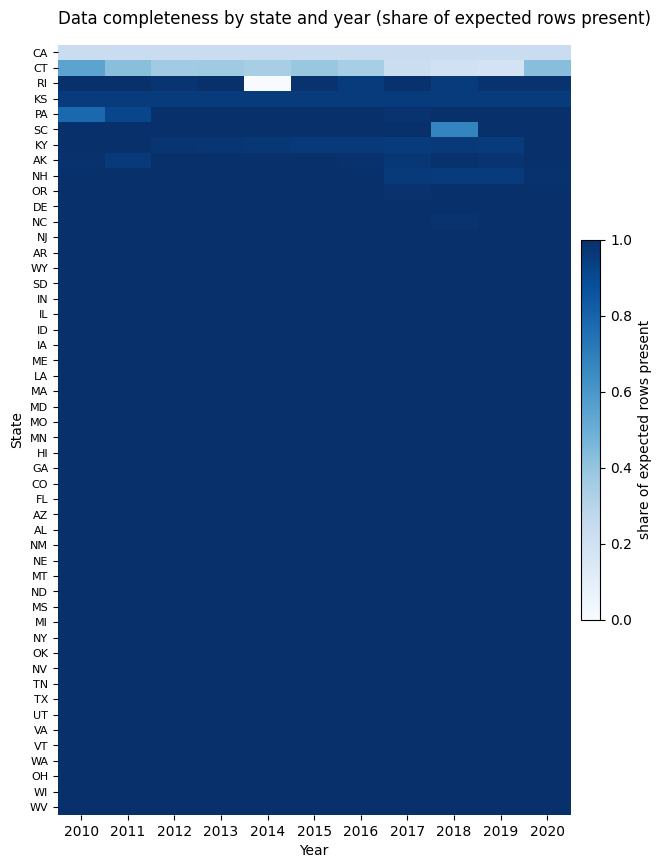

In [5]:
# Grouping by state and year, count rows, and calculate the completeness fraction
completeness = df_risk.groupby(['st', 'year']).size().reset_index(name='count')
completeness['share'] = completeness['count'] / 264.0

# Pivoting the data to create a matrix with states on rows and years on columns
matrix = completeness.pivot(index='st', columns='year', values='share').fillna(0.0)

# Sorting states by average completeness
matrix = matrix.loc[matrix.mean(axis=1).sort_values().index]

# Plotting the heatmap
fig, ax = plt.subplots(figsize=(7, 10))
im = ax.imshow(matrix.values, cmap='Blues', aspect='auto', vmin=0.0, vmax=1.0)
cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cbar.set_label('share of expected rows present')

# Setting years on the x-axis
ax.set_xticks(range(len(matrix.columns)))
ax.set_xticklabels(matrix.columns)
ax.set_xlabel('Year')

# Setting state codes on the y-axis
ax.set_yticks(range(len(matrix.index)))
ax.set_yticklabels(matrix.index, fontsize=8)
ax.set_ylabel('State')

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title('Data completeness by state and year (share of expected rows present)', loc='left', pad=15)

plt.savefig('fig1_completeness.png', dpi=150, bbox_inches='tight')
plt.show()

Figure 1. Share of expected state x month x occupation rows present per state and year, sorted least complete first.

Missing data is concentrated in CA, declining over time in CT and there is no data for RI in 2014, with smaller gaps in single years like PA in 2010-2011 and SC in 2018.



In [6]:
# Printing summary statistics for the risk column and finding the num of rows where risk > 1
print("--- df_risk['risk'] Summary Statistics ---")
print(df_risk['risk'].describe())
outliers = df_risk[df_risk['risk'] > 1]
print(f"\nNumber of rows where risk > 1: {len(outliers)}")

if len(outliers) > 0:
    print("\n--- Counts of risk > 1 by state (st) and occupation (soc) ---")
    print(outliers.groupby(['st', 'soc']).size())

# Rearrange the formula to compute implied employment and add as a new column
# risk = claimants / (claimants + employed) => implied_employed = (claimants / risk) - claimants
df_risk['implied_employed'] = (df_risk['claimants'] / df_risk['risk']) - df_risk['claimants']

# Showing Alabama (AL) rows for Jan 2015
print("\n--- Alabama (AL) Jan 2015 Employment Metrics ---")
al_subset = df_risk[(df_risk['st'] == 'AL') & (df_risk['year'] == 2015) & (df_risk['month'] == 1)]
al_subset_sorted = al_subset[['soc', 'claimants', 'risk', 'implied_employed']].sort_values(by='implied_employed', ascending=False)
display(al_subset_sorted.style.format({
    'claimants': '{:,.0f}',
    'risk': '{:.5f}',
    'implied_employed': '{:,.0f}'
}).hide())

# Sum implied_employed and compare with BLS labor force
total_implied = al_subset_sorted['implied_employed'].sum()
bls_labor_force = 2172619
times_larger = total_implied / bls_labor_force

print(f"\nTotal implied employed across all occupations: {total_implied:,.0f}")
print(f"This is {times_larger:.1f} times larger than Alabama's actual 2015 BLS labour force of 2,172,619.")

--- df_risk['risk'] Summary Statistics ---
count    1.402740e+05
mean     2.617547e-03
std      2.596278e-02
min      1.409497e-07
25%      3.881777e-04
50%      7.501609e-04
75%      1.417753e-03
max      2.416900e+00
Name: risk, dtype: float64

Number of rows where risk > 1: 26

--- Counts of risk > 1 by state (st) and occupation (soc) ---
st  soc
AK  45      9
RI  45     17
dtype: int64

--- Alabama (AL) Jan 2015 Employment Metrics ---


soc,claimants,risk,implied_employed
51,"3,904",0.00045,"8,706,587"
43,"3,566",0.00055,"6,426,993"
29,592,0.00020,"2,897,797"
25,353,0.00013,"2,666,507"
53,"1,796",0.00070,"2,556,259"
49,"1,112",0.00059,"1,888,948"
41,"1,839",0.00103,"1,777,301"
47,"2,731",0.00173,"1,577,048"
35,"1,286",0.00109,"1,182,800"
11,"1,866",0.00196,"947,979"



Total implied employed across all occupations: 34,321,724
This is 15.8 times larger than Alabama's actual 2015 BLS labour force of 2,172,619.


Number of rows with risk above 1 = 26.

All are SOC 45 in Alaska and Rhode Island.

The paper defines risk = claimants / (claimants + employed).
Working back from this gives the employment each row implies. For Alabama in January 2015, these add up to roughly 34.3 million, which is 15.8 times the state's real labour force of 2,172,619 (BLS via FRED).

The authors also describe a Bayesian method using state unemployment rates, which may explain the gap. Either way, the risk column can't be reproduced from the released data.

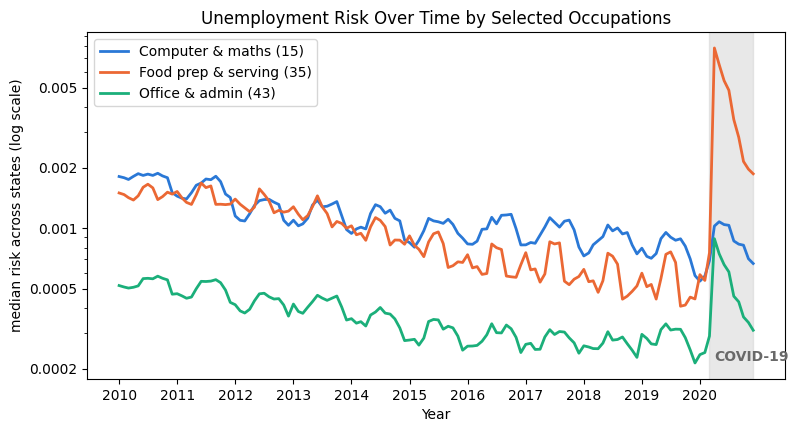

In [7]:
import matplotlib.ticker as ticker

# Creating a date column from year and month and filtering for specific SOC codes
df_risk['date'] = pd.to_datetime(df_risk[['year', 'month']].assign(day=1))
soc_targets = [15, 35, 43]
df_filtered = df_risk[df_risk['soc'].isin(soc_targets)]

# Calculating the median risk across states for each month
trends = df_filtered.groupby(['date', 'soc'])['risk'].median().unstack()

# Mapping SOC codes to descriptive labels
soc_labels = {
    15: 'Computer & maths (15)',
    35: 'Food prep & serving (35)',
    43: 'Office & admin (43)'
}
trends = trends.rename(columns=soc_labels)

# Plotting the lines
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = {
    'Computer & maths (15)': '#2a78d6',
    'Food prep & serving (35)': '#eb6834',
    'Office & admin (43)': '#1baf7a'
}

for col in trends.columns:
    ax.plot(trends.index, trends[col], label=col, color=colors[col], linewidth=2)

# Apply log scale and customized labels/ticks
ax.set_yscale('log')
ax.set_ylabel('median risk across states (log scale)')
ax.set_xlabel('Year')
ax.set_title('Unemployment Risk Over Time by Selected Occupations')

# Customizing y-axis ticks
y_ticks = [0.0002, 0.0005, 0.001, 0.002, 0.005]
ax.set_yticks(y_ticks)
ax.get_yaxis().set_major_formatter(ticker.FormatStrFormatter('%g'))

# Customizing x-axis to show every year from 2010 to 2020
x_ticks = pd.date_range(start='2010-01-01', end='2020-01-01', freq='YS')
ax.set_xticks(x_ticks)
ax.set_xticklabels([str(year) for year in range(2010, 2021)])

ax.legend()

# Shading months March-December 2020 as COVID-19
ax.axvspan(pd.Timestamp('2020-03-01'), pd.Timestamp('2020-12-01'), color='lightgrey', alpha=0.5)
ax.text(pd.Timestamp('2020-04-01'), 0.00022, 'COVID-19', color='dimgrey', fontweight='bold')

# Saving and displaying the figure
plt.savefig('fig2_risk_over_time.png', dpi=150, bbox_inches='tight')
plt.show()

Figure 2. Median unemployment risk across states for three occupation groups.

Risk falls steadily from 2010 to 2019, with a clear yearly cycle in food prep.
In 2020, COVID-19 caused a bigger jump than anything in the previous 10 years.
For food prep, risk in April 2020 was about 14 times higher than its average in 2019.

In [8]:
# Getting score columns and metadata
scores = [col for col in df_auto.columns if col not in ['year', 'state', 'month', 'Unnamed: 0']]
print(f"Number of rows: {len(df_auto)}")
print(f"Number of unique states: {df_auto['state'].nunique()}")
print(f"Number of score columns: {len(scores)}")
print("Score columns:", scores)

# Showing which months appear in each year
print("\nMonths present per year:")
print(df_auto.groupby('year')['month'].unique())

# Printing unique states per year and finding the missing states in 2014
print("\nUnique states per year:")
print(df_auto.groupby('year')['state'].nunique())

states_risk = set(df_risk['st'].unique())
states_auto_2014 = set(df_auto[df_auto['year'] == 2014]['state'])
missing_states = states_risk - states_auto_2014
print(f"\nStates in df_risk missing from df_auto in 2014: {missing_states}")

Number of rows: 549
Number of unique states: 50
Number of score columns: 12
Score columns: ['Acemoglu & Autor Comp.Use', 'Acemoglu & Autor R.Cog.', 'Acemoglu & Autor R.Man.', 'ONET Education %college', 'Frey & Osborne auto', 'Arntz et al auto', 'ONET Automation Deg.Auto.', 'Brynjolfsson et al SML', 'Felten et al AI', 'Webb AI', 'Webb Robot', 'Webb Software']

Months present per year:
year
2010     [1, 2]
2011        [1]
2012     [1, 2]
2013        [1]
2014        [1]
2015     [1, 4]
2016        [1]
2017     [1, 2]
2018    [1, 10]
2019     [1, 8]
2020     [1, 4]
Name: month, dtype: object

Unique states per year:
year
2010    50
2011    50
2012    50
2013    50
2014    49
2015    50
2016    50
2017    50
2018    50
2019    50
2020    50
Name: state, dtype: int64

States in df_risk missing from df_auto in 2014: {'RI'}


There are 12 score columns, but 'ONET Education %college' is a control in the paper, not an exposure score. That leaves 11 exposure scores, while the paper uses 12. Eloundou et al.'s LLM score is missing.

The file isn't monthly. Each year has January and at most one other month, which changes from year to year.

Rhode Island is missing in 2014, the same gap as in the risk file.

In [9]:
# Summary table for scores (mean, min, max) rounded to 3 decimal places
summary_stats = df_auto[scores].agg(['mean', 'min', 'max']).T
display(summary_stats.round(3))

# Showing 6 rows with the lowest Webb AI score
target_cols = ['year', 'month', 'state', 'Frey & Osborne auto', 'Felten et al AI', 'Webb AI']
lowest_webb = df_auto.nsmallest(6, 'Webb AI')[target_cols]
display(lowest_webb)

,mean,min,max
Acemoglu & Autor Comp.Use,0.657,0.040,0.976
Acemoglu & Autor R.Cog.,-0.322,-0.447,0.366
Acemoglu & Autor R.Man.,-0.639,-0.893,-0.037
ONET Education %college,0.396,0.007,0.612
Frey & Osborne auto,0.141,0.003,0.532
Arntz et al auto,0.157,0.003,0.234
ONET Automation Deg.Auto.,0.215,0.006,0.236
Brynjolfsson et al SML,0.553,0.018,0.608
Felten et al AI,3.484,0.124,3.750
Webb AI,64.712,2.633,84.030


,year,month,state,Frey & Osborne auto,Felten et al AI,Webb AI
403,2018,1,CA,0.003182,0.124286,2.632521
503,2020,1,CA,0.122633,1.340452,43.990230
453,2019,1,CA,0.124170,1.379849,45.324965
505,2020,4,CT,0.395281,2.313276,47.133473
455,2019,8,CT,0.397568,2.336606,47.552337
531,2020,1,NV,0.110434,2.927459,54.188372


The scores are on different scales, which is why the paper standardises them before LASSO.

Five of the six lowest values come from California and Connecticut, the two least complete states in the risk file. California's Webb AI score drops to 2.6 in January 2018.

State scores are averaged over each state's occupation mix, so states with missing occupations end up with unreliable scores.

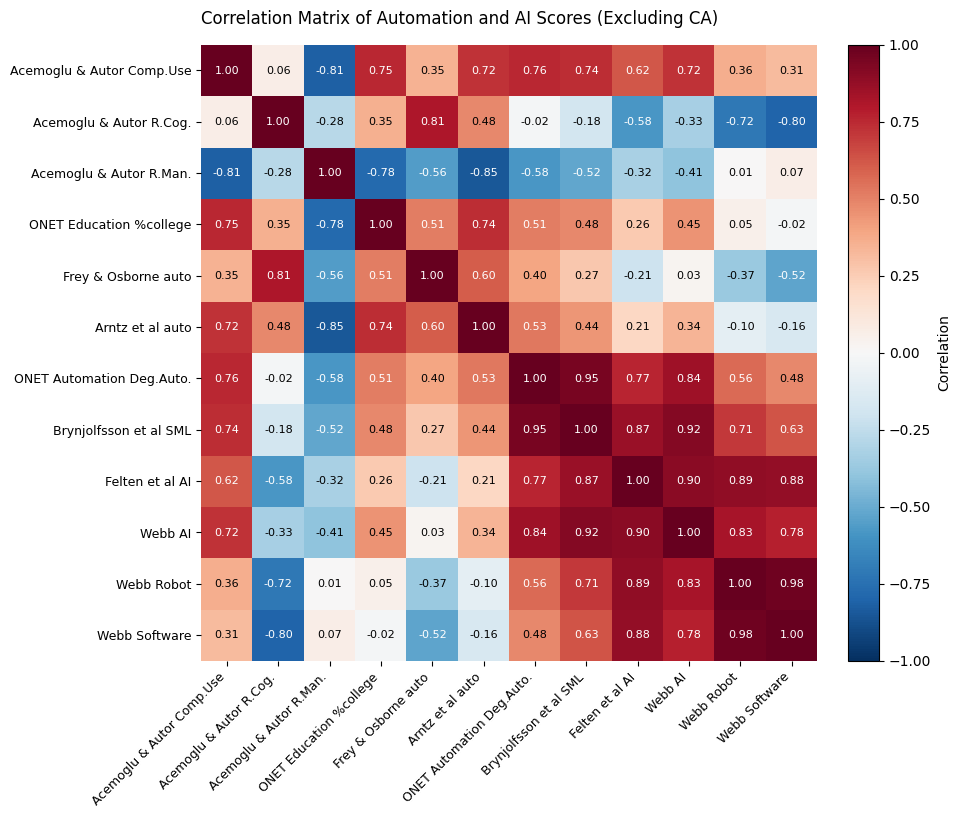

In [10]:
# Correlation heatmap of score columns (excluding California)
df_no_call = df_auto[df_auto['state'] != 'CA']
corr_matrix = df_no_call[scores].corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr_matrix.values, cmap='RdBu_r', vmin=-1.0, vmax=1.0)
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Correlation')

# Setting ticks and labels
ax.set_xticks(range(len(scores)))
ax.set_yticks(range(len(scores)))
ax.set_xticklabels(scores, rotation=45, ha='right', fontsize=9)
ax.set_yticklabels(scores, fontsize=9)

# Annotating the squares with correlation values
for i in range(len(scores)):
    for j in range(len(scores)):
        val = corr_matrix.values[i, j]
        text_color = 'white' if abs(val) > 0.5 else 'black'
        ax.text(j, i, f"{val:.2f}", ha='center', va='center', color=text_color, fontsize=8)
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title('Correlation Matrix of Automation and AI Scores (Excluding CA)', loc='left', pad=15)

plt.savefig('fig3_score_correlations.png', dpi=150, bbox_inches='tight')
plt.show()

Figure 3. Correlation between exposure scores at state level.

California is excluded because its scores are unreliable.

Some scores are almost identical (e.g. Webb Robot and Webb Software, 0.98) and when this happens, LASSO usually keeps one and drops the other at random, so individual coefficients shouldn't be over-read.